In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn



In [59]:
client = pd.read_csv("../data/Client.csv")
record = pd.read_csv("../data/Record.csv")

print("Datasets loaded successfully!")

Datasets loaded successfully!


In [60]:
print("Client Dataset:", client.shape)
print("Record Dataset:", record.shape)

Client Dataset: (100000, 50)
Record Dataset: (100000, 51)


In [61]:
display(client.head())

,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,...,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays,Customer_ID
0,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,...,0.0,N,U,U,U,U,U,Y,361.0,1000001
1,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,...,0.0,Z,U,U,U,U,U,Y,240.0,1000002
2,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,...,0.0,N,U,Y,U,U,U,Y,1504.0,1000003
3,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,...,0.0,U,Y,U,U,U,U,Y,1812.0,1000004
4,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,...,0.0,I,U,U,U,U,U,Y,434.0,1000005


In [62]:
display(record.head())

,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,...,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,...,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,...,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,...,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,...,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1000004
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,...,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1000005


In [63]:
# Dataset Information Summary

def dataset_summary(df, name):
    summary = pd.DataFrame({
        "Dataset": [name],
        "Rows": [df.shape[0]],
        "Columns": [df.shape[1]],
        "Missing Values": [df.isnull().sum().sum()],
        "Duplicate Rows": [df.duplicated().sum()],
        "Memory Usage (MB)": [
            round(df.memory_usage(deep=True).sum() / (1024**2), 2)
        ]
    })

    return summary


display(dataset_summary(client, "Client Dataset"))
display(dataset_summary(record, "Record Dataset"))

,Dataset,Rows,Columns,Missing Values,Duplicate Rows,Memory Usage (MB)
0,Client Dataset,100000,50,337974,0,120.73


,Dataset,Rows,Columns,Missing Values,Duplicate Rows,Memory Usage (MB)
0,Record Dataset,100000,51,4995,0,38.91


In [64]:
print("CLIENT DATASET COLUMNS")
print(client.columns.tolist())

CLIENT DATASET COLUMNS
['uniqsubs', 'actvsubs', 'new_cell', 'crclscod', 'asl_flag', 'totcalls', 'totmou', 'totrev', 'adjrev', 'adjmou', 'adjqty', 'avgrev', 'avgmou', 'avgqty', 'avg3mou', 'avg3qty', 'avg3rev', 'avg6mou', 'avg6qty', 'avg6rev', 'prizm_social_one', 'area', 'dualband', 'refurb_new', 'hnd_price', 'phones', 'models', 'hnd_webcap', 'truck', 'rv', 'ownrent', 'lor', 'dwlltype', 'marital', 'adults', 'infobase', 'income', 'numbcars', 'HHstatin', 'dwllsize', 'forgntvl', 'ethnic', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd', 'eqpdays', 'Customer_ID']


In [65]:
print("RECORD DATASET COLUMNS")
print(record.columns.tolist())

RECORD DATASET COLUMNS
['rev_Mean', 'mou_Mean', 'totmrc_Mean', 'da_Mean', 'ovrmou_Mean', 'ovrrev_Mean', 'vceovr_Mean', 'datovr_Mean', 'roam_Mean', 'change_mou', 'change_rev', 'drop_vce_Mean', 'drop_dat_Mean', 'blck_vce_Mean', 'blck_dat_Mean', 'unan_vce_Mean', 'unan_dat_Mean', 'plcd_vce_Mean', 'plcd_dat_Mean', 'recv_vce_Mean', 'recv_sms_Mean', 'comp_vce_Mean', 'comp_dat_Mean', 'custcare_Mean', 'ccrndmou_Mean', 'cc_mou_Mean', 'inonemin_Mean', 'threeway_Mean', 'mou_cvce_Mean', 'mou_cdat_Mean', 'mou_rvce_Mean', 'owylis_vce_Mean', 'mouowylisv_Mean', 'iwylis_vce_Mean', 'mouiwylisv_Mean', 'peak_vce_Mean', 'peak_dat_Mean', 'mou_peav_Mean', 'mou_pead_Mean', 'opk_vce_Mean', 'opk_dat_Mean', 'mou_opkv_Mean', 'mou_opkd_Mean', 'drop_blk_Mean', 'attempt_Mean', 'complete_Mean', 'callfwdv_Mean', 'callwait_Mean', 'churn', 'months', 'Customer_ID']


In [66]:
print("Client Unique IDs:",
      client["Customer_ID"].is_unique)

print("Record Unique IDs:",
      record["Customer_ID"].is_unique)

Client Unique IDs: True
Record Unique IDs: True


In [67]:
client_missing = client.isnull().sum()
record_missing = record.isnull().sum()

print("Missing Values in Client Dataset:")
print(client_missing[client_missing > 0].sort_values(ascending=False).to_string())

print("\nMissing Values in Record Dataset:")
print(record_missing[record_missing > 0].sort_values(ascending=False).to_string())


Missing Values in Client Dataset:
numbcars            49366
dwllsize            38308
HHstatin            37923
ownrent             33706
dwlltype            31909
lor                 30190
income              25436
adults              23019
infobase            22079
hnd_webcap          10189
prizm_social_one     7388
avg6mou              2839
avg6qty              2839
avg6rev              2839
truck                1732
rv                   1732
ethnic               1732
kid0_2               1732
kid3_5               1732
kid6_10              1732
kid11_15             1732
kid16_17             1732
marital              1732
forgntvl             1732
creditcd             1732
hnd_price             847
area                   40
refurb_new              1
models                  1
phones                  1
dualband                1
eqpdays                 1

Missing Values in Record Dataset:
change_mou     891
change_rev     891
rev_Mean       357
totmrc_Mean    357
mou_Mean       357
da_M

In [68]:
client_missing_percent = (client.isnull().mean() * 100)

record_missing_percent = (record.isnull().mean() * 100)

print("Client Missing Value Percentage")
print(client_missing_percent[client_missing_percent > 0].sort_values(ascending=False).round(2).to_string())

print("\nRecord Missing Value Percentage")
print(record_missing_percent[record_missing_percent > 0].sort_values(ascending=False).round(2).to_string())

Client Missing Value Percentage
numbcars            49.37
dwllsize            38.31
HHstatin            37.92
ownrent             33.71
dwlltype            31.91
lor                 30.19
income              25.44
adults              23.02
infobase            22.08
hnd_webcap          10.19
prizm_social_one     7.39
avg6mou              2.84
avg6qty              2.84
avg6rev              2.84
truck                1.73
rv                   1.73
ethnic               1.73
kid0_2               1.73
kid3_5               1.73
kid6_10              1.73
kid11_15             1.73
kid16_17             1.73
marital              1.73
forgntvl             1.73
creditcd             1.73
hnd_price            0.85
area                 0.04
refurb_new           0.00
models               0.00
phones               0.00
dualband             0.00
eqpdays              0.00

Record Missing Value Percentage
change_mou     0.89
change_rev     0.89
rev_Mean       0.36
totmrc_Mean    0.36
mou_Mean       0.36
da_

In [69]:
print("Is churn in Client?", "churn" in client.columns)

print("Is churn in Record?", "churn" in record.columns)

Is churn in Client? False
Is churn in Record? True


In [70]:
common_columns = set(client.columns) & set(record.columns)

print("Common Columns:")
print(sorted(common_columns))

Common Columns:
['Customer_ID']


In [71]:
# ///churn counts
print(record["churn"].value_counts().to_string())

churn
0    50438
1    49562


In [72]:
# churn parcentage
churn_percentage = (
    record["churn"].value_counts(normalize=True) * 100
)

print(churn_percentage.round(2).to_string())

churn
0    50.44
1    49.56


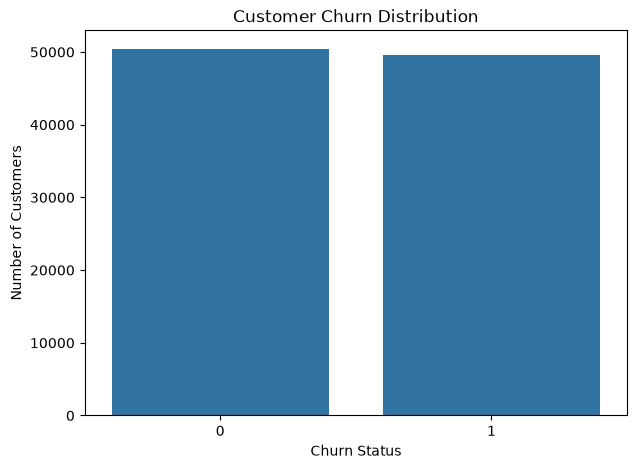

In [73]:
# churn graph
plt.figure(figsize=(7, 5))

sns.countplot(data=record, x="churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()


In [74]:
# ID Matching before merging the datasets
print("Client IDs:", len(client["Customer_ID"]))
print("Record IDs:", len(record["Customer_ID"]))

print("Matching IDs:", client["Customer_ID"].isin(record["Customer_ID"]).sum())

Client IDs: 100000
Record IDs: 100000
Matching IDs: 100000


In [75]:
#Dataset merging
df = pd.merge(client, record, on="Customer_ID", how="inner",validate="one_to_one")
print("Merged Dataset Successfully!")
print("Merged Dataset Shape:", df.shape)

Merged Dataset Successfully!
Merged Dataset Shape: (100000, 100)


In [76]:
#Merged Dataset
display(df.head())

,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,...,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months
0,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,...,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61
1,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,...,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56
2,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,...,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58
3,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,...,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60
4,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,...,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57


In [77]:
print("Total Rows in Merged Dataset:", df.shape[0])
print("Total Columns in Merged Dataset:", df.shape[1])
print("Total Missing Values:", df.isnull().sum().sum())

Total Rows in Merged Dataset: 100000
Total Columns in Merged Dataset: 100
Total Missing Values: 342969


In [78]:
#Missing values Summary
missing_summary = pd.DataFrame({"Missing_Count": df.isnull().sum(), "Missing_Percentage": (df.isnull().mean() * 100)})

missing_summary = missing_summary.sort_values(by="Missing_Percentage", ascending=False)
display(missing_summary.head(20).round(2))

,Missing_Count,Missing_Percentage
numbcars,49366,49.37
dwllsize,38308,38.31
HHstatin,37923,37.92
ownrent,33706,33.71
dwlltype,31909,31.91
lor,30190,30.19
income,25436,25.44
adults,23019,23.02
infobase,22079,22.08
hnd_webcap,10189,10.19


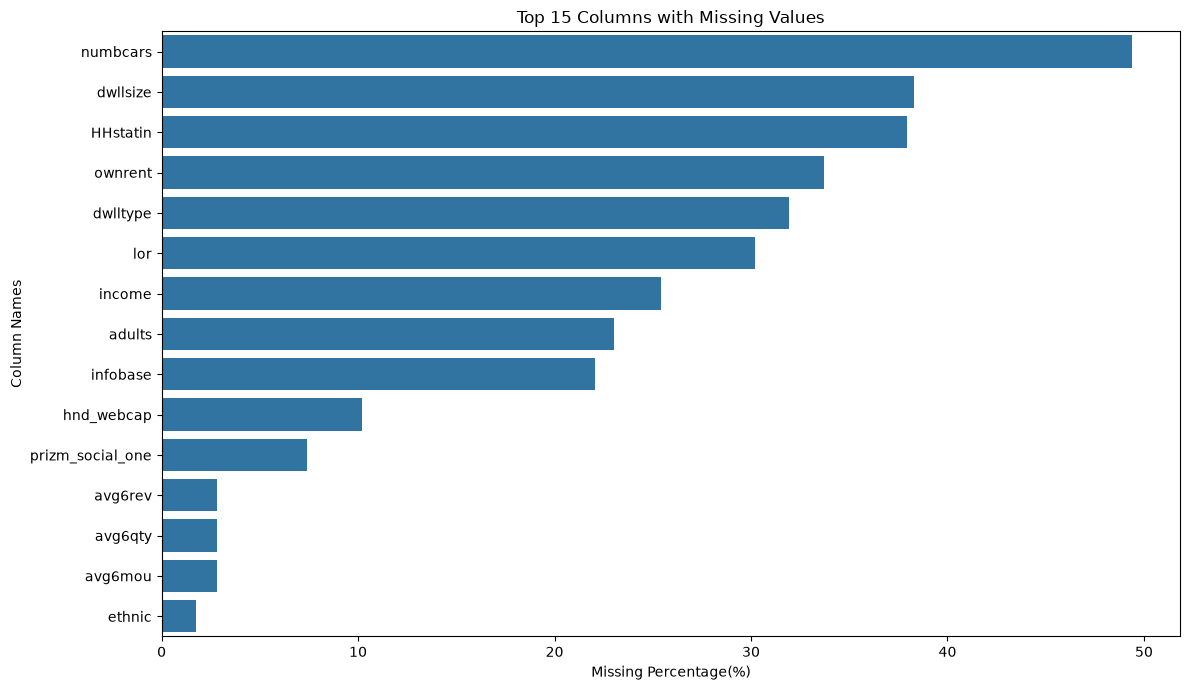

In [79]:
#Visulaization of missing values  (A horizontal bar chart showing the top 15 columns with missing values)
plt.figure(figsize=(12, 7))

top_missing = missing_summary.head(15)
sns.barplot(x=top_missing["Missing_Percentage"], y=top_missing.index)

plt.title("Top 15 Columns with Missing Values")
plt.xlabel("Missing Percentage(%)")
plt.ylabel("Column Names")

plt.tight_layout()
plt.show()

In [80]:
print("Available DataFrames:")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(name, obj.shape)

Available DataFrames:
client (100000, 50)
record (100000, 51)
df (100000, 100)
churn_comparison (2, 8)
marital_churn (5, 3)
adults_churn (6, 3)
result (2, 3)
numerical_df (100000, 79)
correlation (79, 79)
equipment_analysis (4, 3)
equipment_churn_table (4, 2)
revenue_analysis (4, 3)
revenue_table (4, 2)
tenure_analysis (4, 3)
tenure_table (4, 2)
comparison (3, 6)
missing_summary (100, 2)
top_missing (15, 2)


In [81]:
# Comparison Datasets with Churn

print("Churn Column Exists:", "churn" in df.columns)

print("\nChurn Distribution:")
print(df["churn"].value_counts().to_string())

print("\nChurn Percentage:")
print(
    (df["churn"].value_counts(normalize=True) * 100)
    .round(2)
    .to_string()
)

Churn Column Exists: True

Churn Distribution:
churn
0    50438
1    49562

Churn Percentage:
churn
0    50.44
1    49.56


In [82]:
# Compare customer behavior by churn status

features = [
    "rev_Mean", #average revenue
    "mou_Mean", #average minutes of use
    "change_mou", #change in minutes of use
    "change_rev", #change in revenue
    "drop_vce_Mean", #average number of dropped calls
    "custcare_Mean", #average customer care interactions
    "months", #number of months
    "eqpdays" #number of days since equipment installation
]

# Select only columns available in our dataset
available_features = [col for col in features if col in df.columns]

churn_comparison = df.groupby("churn")[available_features].mean()

display(churn_comparison.T.round(2))

churn,0,1
rev_Mean,59.22,58.21
mou_Mean,543.21,483.31
change_mou,-5.34,-22.76
change_rev,-1.41,-0.62
drop_vce_Mean,6.09,5.82
custcare_Mean,1.98,1.60
months,18.63,19.04
eqpdays,363.28,421.09


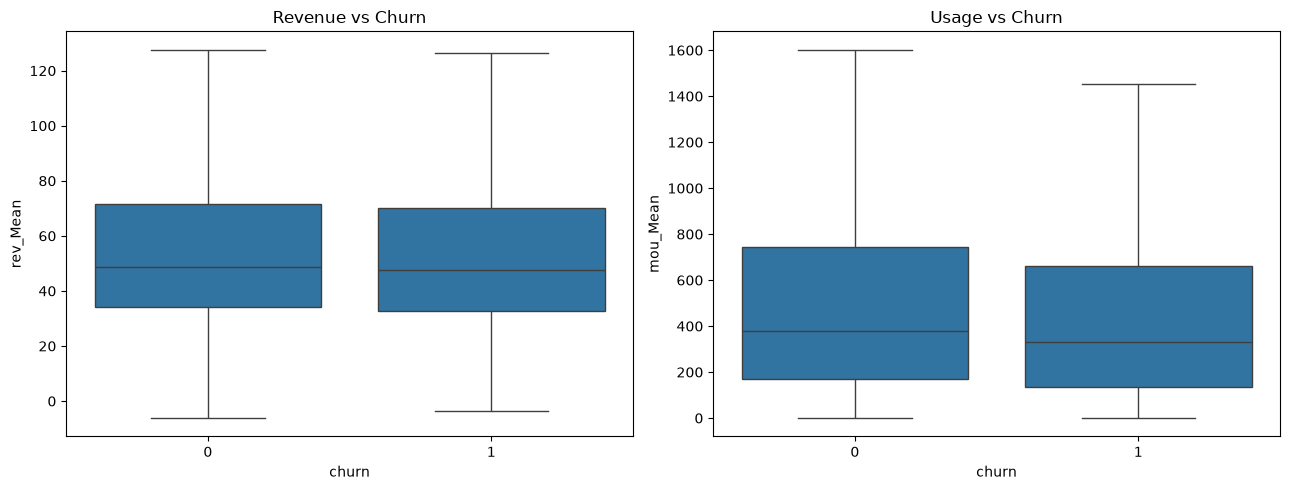

In [83]:
#customer usages visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x="churn", y="rev_Mean",ax=axes[0], showfliers=False) #boxplot = By comparing the data disribution of two types of customers. 

axes[0].set_title("Revenue vs Churn")

sns.boxplot(data=df, x="churn", y="mou_Mean",ax=axes[1], showfliers=False)

axes[1].set_title("Usage vs Churn")

plt.tight_layout()
plt.show()

In [84]:
# Create Usage Change Group

df["usage_group"] = pd.cut(
    df["change_mou"],
    bins=[-float("inf"), -50, -10, 0, float("inf")],
    labels=[
        "High Decrease",
        "Moderate Decrease",
        "Slight Decrease",
        "Increase"
    ]
)

print(df["usage_group"].value_counts().to_string())

usage_group
Increase             43702
High Decrease        32980
Moderate Decrease    14646
Slight Decrease       7781


In [85]:
# Calculate churn rate for each usage group

usage_churn = (
    df.groupby("usage_group", observed=False)["churn"]
    .mean() * 100
)

print("Churn Rate by Usage Group:")
print(usage_churn.round(2).to_string())

Churn Rate by Usage Group:
usage_group
High Decrease        52.29
Moderate Decrease    49.26
Slight Decrease      55.53
Increase             46.00


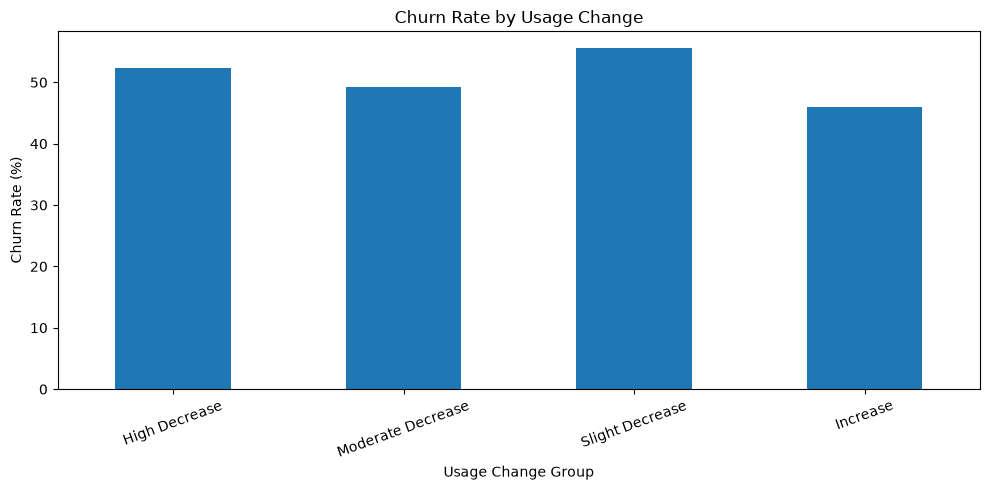

In [86]:
#Graphical representation of usage change group
plt.figure(figsize=(10, 5))

usage_churn.plot(kind="bar")

plt.title("Churn Rate by Usage Change")
plt.xlabel("Usage Change Group")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [87]:
# Customer Care Service Group

df["care_group"] = pd.cut(
    df["custcare_Mean"],
    bins=[-float("inf"), 1, 3, float("inf")],
    labels=[
        "Low Interaction",
        "Medium Interaction",
        "High Interaction"
    ]
)

print(df["care_group"].value_counts().to_string())

care_group
Low Interaction       71792
High Interaction      16022
Medium Interaction    12186


In [88]:
# Calculate churn rate for each customer care group

care_churn = (
    df.groupby("care_group", observed=False)["churn"]
    .mean() * 100
)

print("Churn Rate by Customer Care:")
print(care_churn.round(2).to_string())

Churn Rate by Customer Care:
care_group
Low Interaction       51.23
Medium Interaction    46.18
High Interaction      44.66


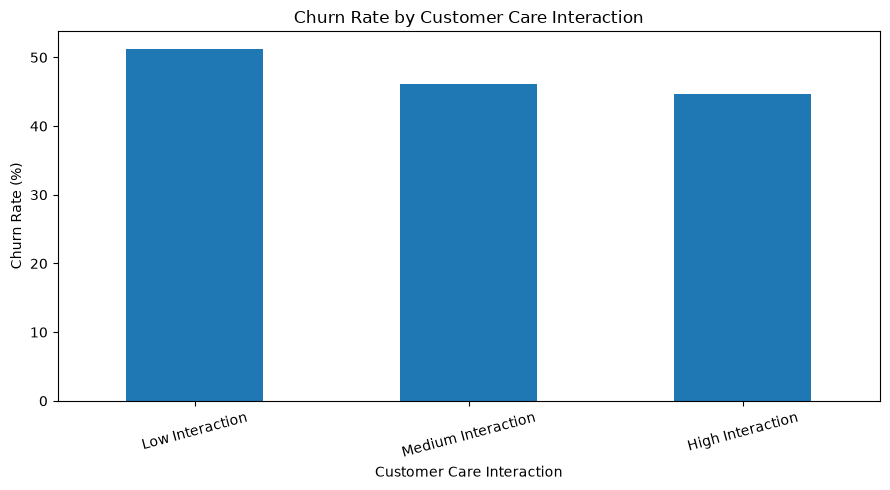

In [89]:
#Visualization by Graphical representation of customer care service group
plt.figure(figsize=(9, 5))

care_churn.plot(kind="bar")

plt.title("Churn Rate by Customer Care Interaction")
plt.xlabel("Customer Care Interaction")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [90]:
# Customer Tenure Group

df["tenure_group"] = pd.cut(
    df["months"],
    bins=[-float("inf"), 6, 12, 24, float("inf")],
    labels=[
        "0-6 Months",
        "7-12 Months",
        "13-24 Months",
        "Above 24 Months"
    ]
)

print(df["tenure_group"].value_counts().to_string())

tenure_group
13-24 Months       42868
7-12 Months        31148
Above 24 Months    24689
0-6 Months          1295


In [91]:
# Churn Rate for each customer tenure group

tenure_churn = (
    df.groupby("tenure_group", observed=False)["churn"]
    .mean() * 100
)

print("Churn Rate by Customer Tenure:")
print(tenure_churn.round(2).to_string())

Churn Rate by Customer Tenure:
tenure_group
0-6 Months         38.38
7-12 Months        47.13
13-24 Months       51.78
Above 24 Months    49.37


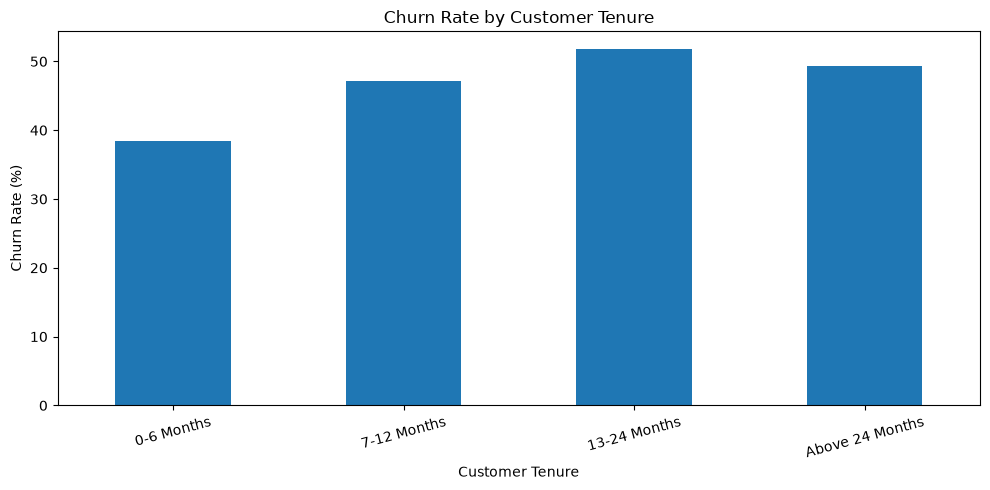

In [92]:
#Graphical representation of churn rate by usage group
plt.figure(figsize=(10, 5))

tenure_churn.plot(kind="bar")

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [93]:
#Revenue Group
df["revenue_group"] = pd.qcut(
    df["rev_Mean"],
    q=4,
    labels=[
        "Low Revenue",
        "Medium Revenue",
        "High Revenue",
        "Very High Revenue"
    ]
)

print(df["revenue_group"].value_counts().to_string())

revenue_group
Low Revenue          24921
High Revenue         24911
Very High Revenue    24910
Medium Revenue       24901


In [94]:
#Churn Rate according to revenue group
revenue_churn = (
    df.groupby("revenue_group", observed=False)["churn"]
    .mean() * 100
)

print("Churn Rate by Revenue:")
print(revenue_churn.round(2).to_string())

Churn Rate by Revenue:
revenue_group
Low Revenue          52.65
Medium Revenue       47.70
High Revenue         49.01
Very High Revenue    48.61


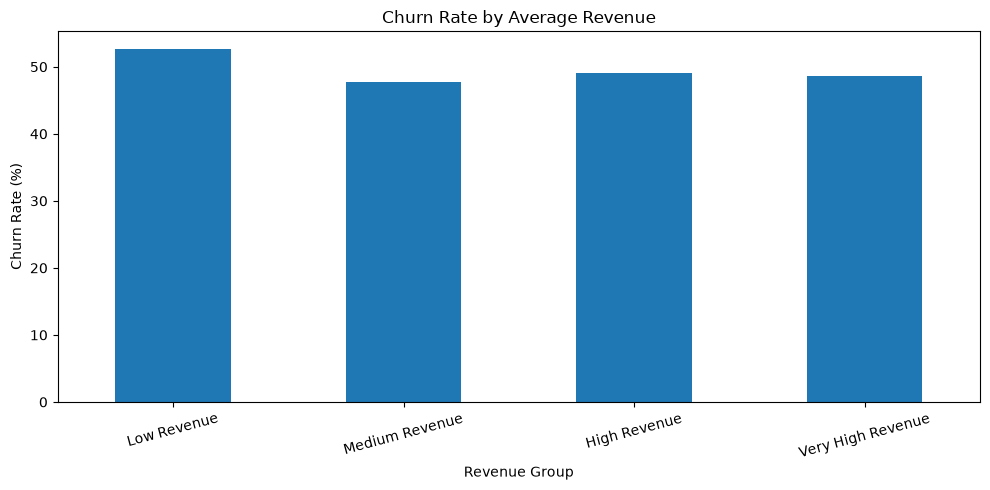

In [95]:
#Graph
plt.figure(figsize=(10, 5))

revenue_churn.plot(kind="bar")

plt.title("Churn Rate by Average Revenue")
plt.xlabel("Revenue Group")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [96]:
#Equipment Age Group
df["equipment_group"] = pd.cut(
    df["eqpdays"],
    bins=[-float("inf"), 180, 365, 730, float("inf")],
    labels=[
        "New Equipment",
        "1 Year Old",
        "1-2 Years Old",
        "Above 2 Years"
    ]
)

print(df["equipment_group"].value_counts().to_string())

equipment_group
1 Year Old       36356
1-2 Years Old    34505
New Equipment    18327
Above 2 Years    10811


In [97]:
#Churn Rate 
equipment_churn = (
    df.groupby("equipment_group", observed=False)["churn"]
    .mean() * 100
)

print("Churn Rate by Equipment Age:")
print(equipment_churn.round(2).to_string())

Churn Rate by Equipment Age:
equipment_group
New Equipment    41.74
1 Year Old       46.97
1-2 Years Old    53.84
Above 2 Years    57.89


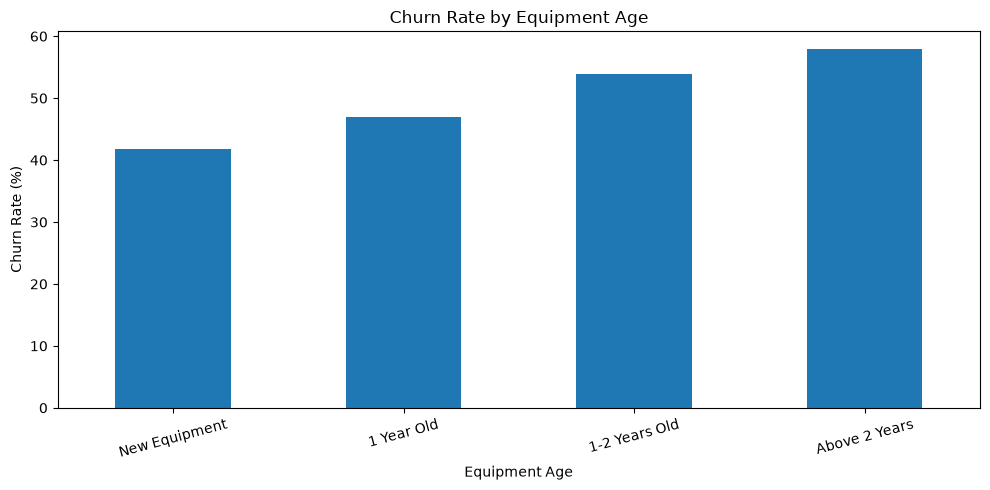

In [98]:
#Visualization 
plt.figure(figsize=(10, 5))

equipment_churn.plot(kind="bar")

plt.title("Churn Rate by Equipment Age")
plt.xlabel("Equipment Age")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [99]:
#Customer Demographics vs Churn
print("Available Demographic Columns:")

demographic_cols = [
    "age",
    "marital",
    "adults",
    "kid0_2",
    "kid3_5",
    "kid6_10",
    "kid11_15",
    "kid16_17",
    "ethnic"
]

for col in demographic_cols:
    if col in df.columns:
        print(col, "Available")

Available Demographic Columns:
marital Available
adults Available
kid0_2 Available
kid3_5 Available
kid6_10 Available
kid11_15 Available
kid16_17 Available
ethnic Available


In [100]:
# Churn Rate by Marital Status

marital_churn = (
    df.groupby("marital", observed=True)["churn"]
    .agg(["count", "mean"])
)

marital_churn["churn_rate"] = marital_churn["mean"] * 100

print("Churn Rate by Marital Status:")
display(marital_churn[["count", "churn_rate"]].round(2))

Churn Rate by Marital Status:


,count,churn_rate
marital,,
A,5140,48.97
B,7116,49.69
M,31052,48.87
S,17627,47.47
U,37333,51.27


In [101]:
# Churn Rate by Number of Adults

adults_churn = (
    df.groupby("adults", observed=True)["churn"]
    .agg(["count", "mean"])
)

adults_churn["churn_rate"] = adults_churn["mean"] * 100

print("Churn Rate by Number of Adults:")
display(adults_churn[["count", "churn_rate"]].round(2))

Churn Rate by Number of Adults:


,count,churn_rate
adults,,
1.0,22299,49.06
2.0,23045,49.49
3.0,13667,48.76
4.0,8803,48.03
5.0,4817,48.56
6.0,4350,47.86


In [102]:
# Churn Rate by Children Information

kid_columns = [
    "kid0_2",
    "kid3_5",
    "kid6_10",
    "kid11_15",
    "kid16_17"
]

for col in kid_columns:

    print("\nChurn Rate by", col)

    result = (
        df.groupby(col, observed=True)["churn"]
        .agg(["count", "mean"])
    )

    result["churn_rate"] = result["mean"] * 100

    display(result[["count", "churn_rate"]].round(2))
    


Churn Rate by kid0_2


,count,churn_rate
kid0_2,,
U,94256,49.49
Y,4012,51.94



Churn Rate by kid3_5


,count,churn_rate
kid3_5,,
U,93572,49.54
Y,4696,50.64



Churn Rate by kid6_10


,count,churn_rate
kid6_10,,
U,90195,49.62
Y,8073,49.24



Churn Rate by kid11_15


,count,churn_rate
kid11_15,,
U,89454,49.65
Y,8814,49.04



Churn Rate by kid16_17


,count,churn_rate
kid16_17,,
U,88304,49.52
Y,9964,50.22


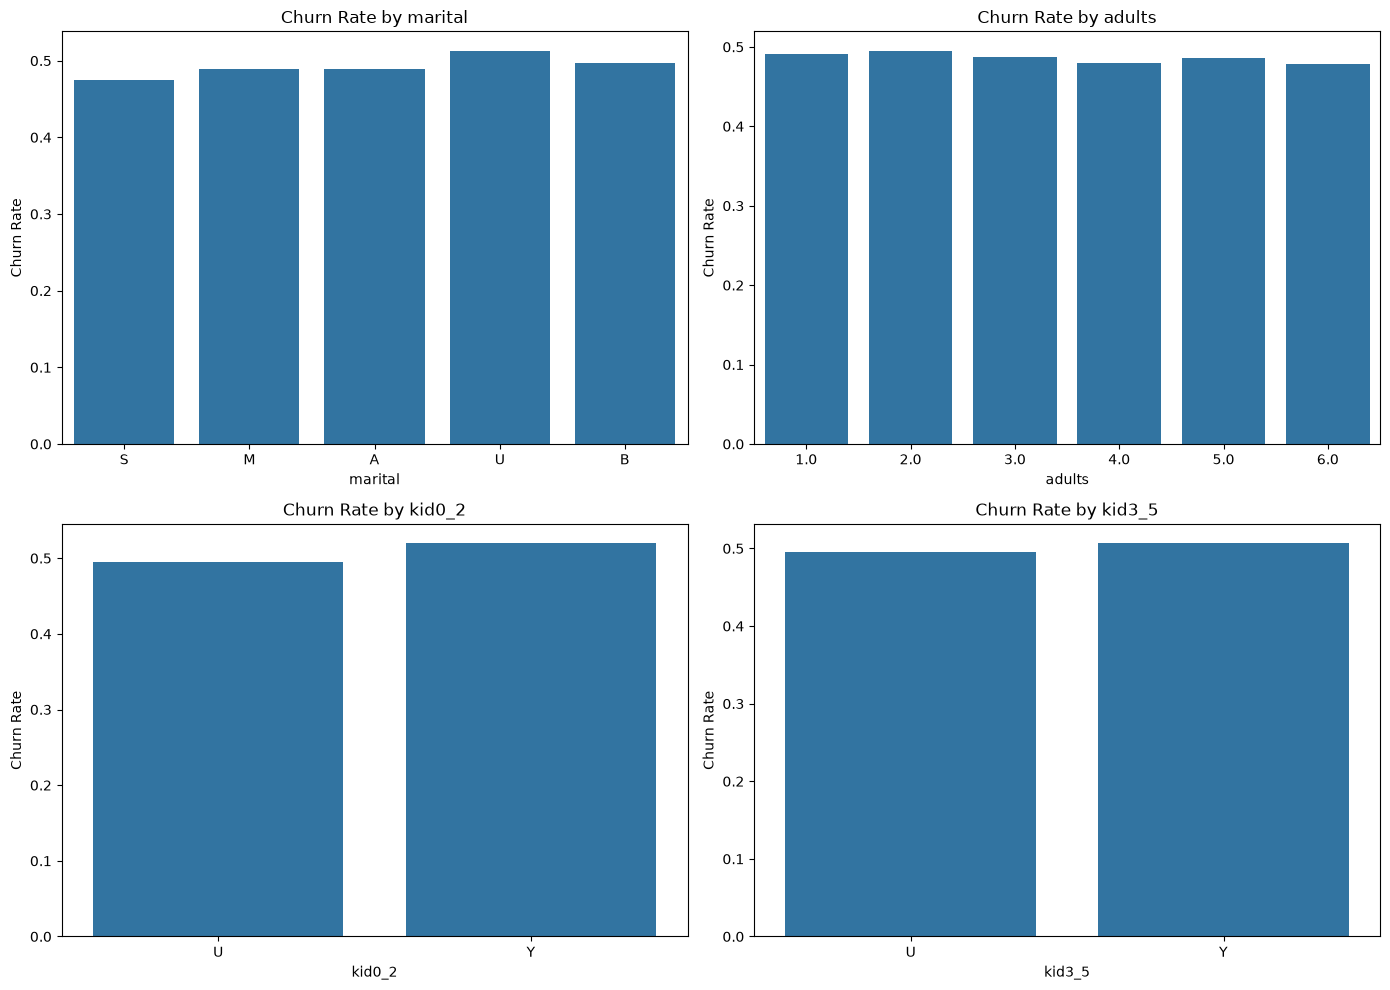

In [103]:
# Demographic Churn Analysis

demographic_features = [
    "marital",
    "adults",
    "kid0_2",
    "kid3_5",
    "kid6_10",
    "kid11_15",
    "kid16_17"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flat, demographic_features[:4]):

    sns.barplot(
        data=df,
        x=col,
        y="churn",
        ax=ax,
        errorbar=None
    )

    ax.set_title(f"Churn Rate by {col}")
    ax.set_ylabel("Churn Rate")

plt.tight_layout()
plt.show()

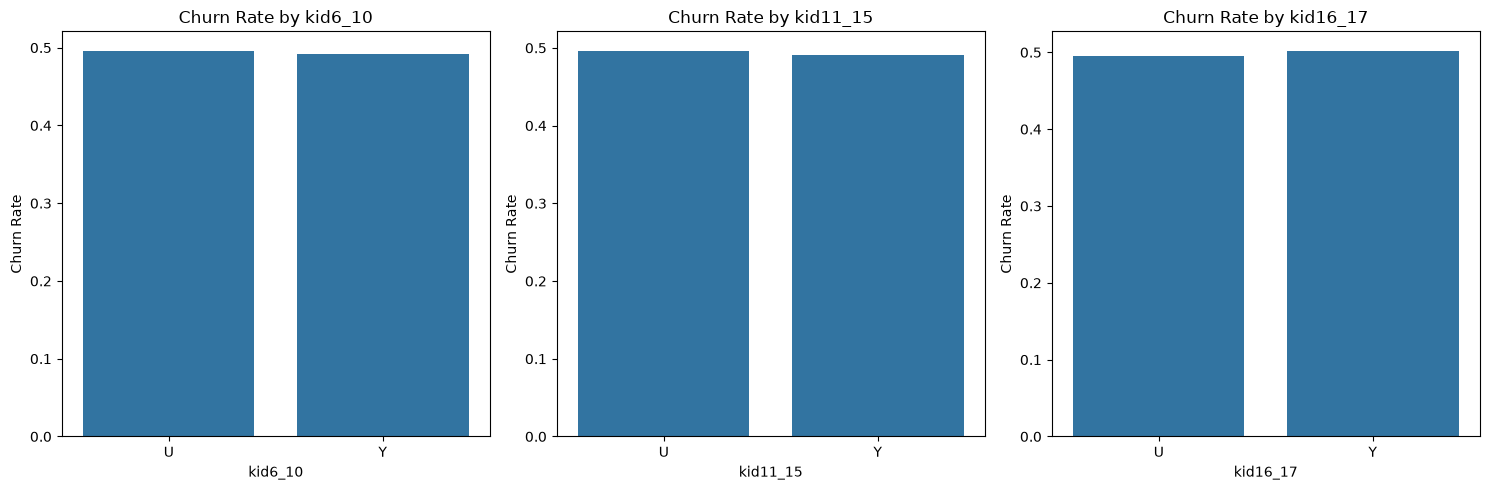

In [104]:
# Remaining Demographic Features

remaining_features = [
    "kid6_10",
    "kid11_15",
    "kid16_17"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, remaining_features):

    sns.barplot(
        data=df,
        x=col,
        y="churn",
        ax=ax,
        errorbar=None
    )

    ax.set_title(f"Churn Rate by {col}")
    ax.set_ylabel("Churn Rate")

plt.tight_layout()
plt.show()

In [105]:
# Correlation Analysis

numerical_df = df.select_dtypes(include=["int64", "float64"])

correlation = numerical_df.corr()

churn_correlation = (
    correlation["churn"]
    .drop("churn")
    .sort_values(ascending=False)
)

print("Top Positive Correlations with Churn:")
display(churn_correlation.head(15).round(3).to_string())

print("\nTop Negative Correlations with Churn:")
display(churn_correlation.tail(15).round(3).to_string())

Top Positive Correlations with Churn:


'eqpdays          0.113\nuniqsubs         0.040\nvceovr_Mean      0.024\novrrev_Mean      0.024\nmonths           0.021\novrmou_Mean      0.020\nactvsubs         0.020\nroam_Mean        0.009\nchange_rev       0.008\nincome           0.005\nnumbcars         0.002\nrv               0.000\nrecv_sms_Mean   -0.001\ndatovr_Mean     -0.001\ncallfwdv_Mean   -0.002'


Top Negative Correlations with Churn:


'models          -0.045\nmou_rvce_Mean   -0.047\nmou_peav_Mean   -0.047\nopk_vce_Mean    -0.048\npeak_vce_Mean   -0.048\nplcd_vce_Mean   -0.048\nattempt_Mean    -0.049\nmou_opkv_Mean   -0.049\navg3mou         -0.050\ncomp_vce_Mean   -0.052\ncomplete_Mean   -0.052\nmou_cvce_Mean   -0.052\nmou_Mean        -0.057\ntotmrc_Mean     -0.069\nhnd_price       -0.103'

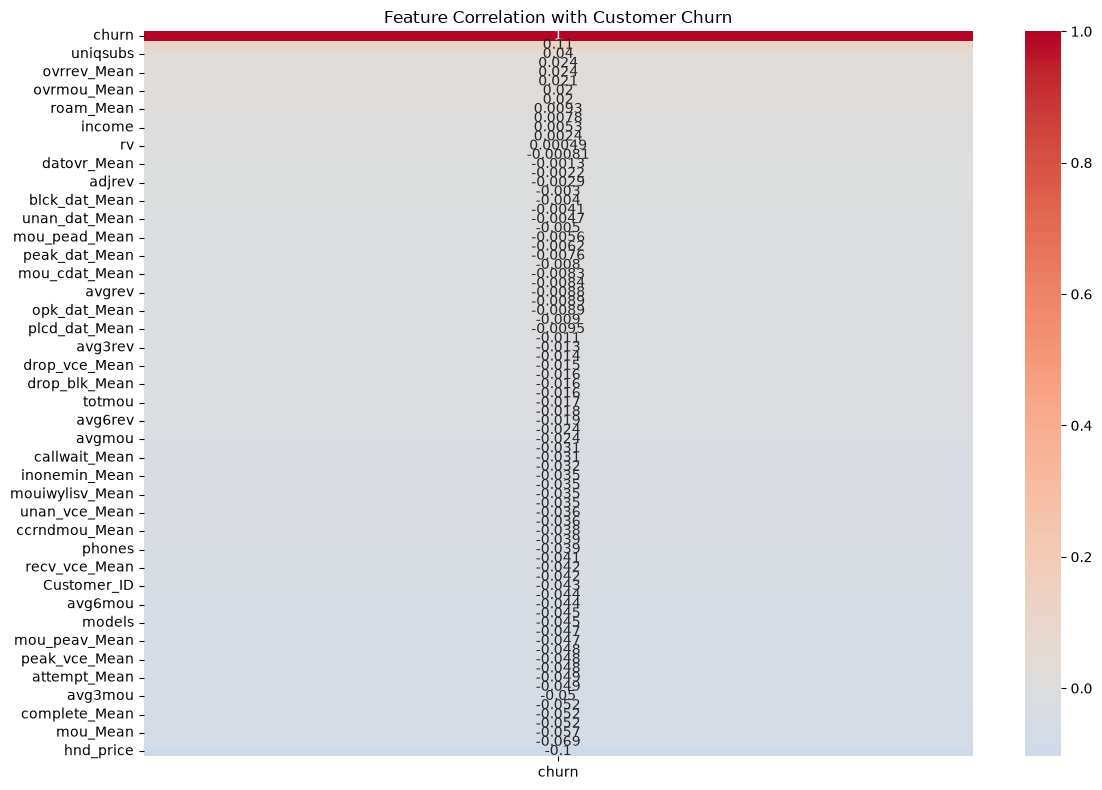

In [106]:
# Correlation Heatmap

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation[["churn"]].sort_values(
        by="churn",
        ascending=False
    ),
    annot=True,
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation with Customer Churn")
plt.tight_layout()
plt.show()

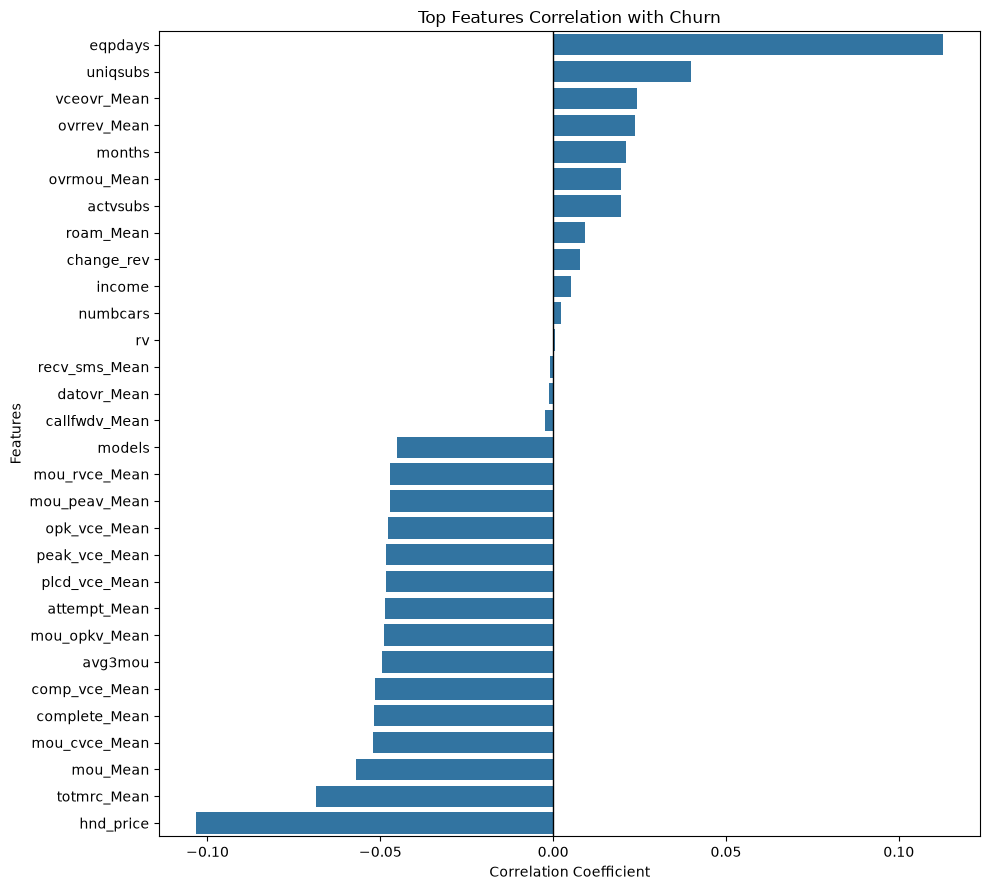

In [107]:
# Top 15 Features Correlation with Churn

top_features = pd.concat([
    churn_correlation.head(15),
    churn_correlation.tail(15)
])

plt.figure(figsize=(10, 9))

sns.barplot(
    x=top_features.values,
    y=top_features.index
)

plt.title("Top Features Correlation with Churn")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Features")

plt.axvline(x=0, color="black", linewidth=1)

plt.tight_layout()
plt.show()

In [108]:
# Equipment Age vs Customer Churn

equipment_analysis = (
    df.groupby("equipment_group", observed=True)["churn"]
    .agg(
        total_customers="count",
        churned_customers="sum",
        churn_rate="mean"
    )
)

equipment_analysis["churn_rate"] *= 100

display(equipment_analysis.round(2))

,total_customers,churned_customers,churn_rate
equipment_group,,,
New Equipment,18327,7649,41.74
1 Year Old,36356,17077,46.97
1-2 Years Old,34505,18577,53.84
Above 2 Years,10811,6259,57.89


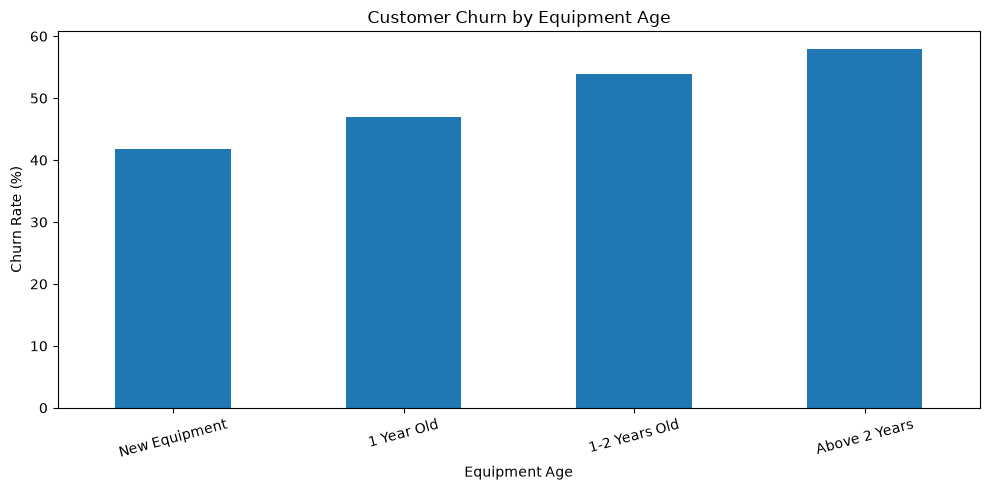

In [109]:
# Equipment Age and Churn Comparison

equipment_analysis["churn_rate"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Customer Churn by Equipment Age")
plt.xlabel("Equipment Age")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [110]:
from scipy.stats import chi2_contingency

# Create contingency table
equipment_churn_table = pd.crosstab(
    df["equipment_group"],
    df["churn"]
)

print("Equipment Age vs Churn:")
display(equipment_churn_table)

# Chi-Square Test
chi2, p_value, dof, expected = chi2_contingency(
    equipment_churn_table
)

print("Chi-Square Statistic:", chi2)
print("P-value:", p_value)
print("Degrees of Freedom:", dof)

if p_value < 0.05:
    print("Result: Statistically Significant Association")
else:
    print("Result: No Statistically Significant Association")

Equipment Age vs Churn:


churn,0,1
equipment_group,,
New Equipment,10678,7649
1 Year Old,19279,17077
1-2 Years Old,15928,18577
Above 2 Years,4552,6259


Chi-Square Statistic: 1099.3107452465624
P-value: 5.135698765860835e-238
Degrees of Freedom: 3
Result: Statistically Significant Association


In [111]:
import numpy as np

# Calculate Cramer's V

n = equipment_churn_table.to_numpy().sum()

min_dimension = min(
    equipment_churn_table.shape[0] - 1,
    equipment_churn_table.shape[1] - 1
)

cramers_v = np.sqrt(
    chi2 / (n * min_dimension)
)

print("Cramer's V:", round(cramers_v, 4))

if cramers_v < 0.1:
    print("Association Strength: Very Weak")
elif cramers_v < 0.3:
    print("Association Strength: Weak")
elif cramers_v < 0.5:
    print("Association Strength: Moderate")
else:
    print("Association Strength: Strong")

Cramer's V: 0.1048
Association Strength: Weak


In [112]:
# Revenue Group Analysis

revenue_analysis = (
    df.groupby("revenue_group", observed=True)["churn"]
    .agg(
        total_customers="count",
        churned_customers="sum",
        churn_rate="mean"
    )
)

revenue_analysis["churn_rate"] *= 100

display(revenue_analysis.round(2))

,total_customers,churned_customers,churn_rate
revenue_group,,,
Low Revenue,24921,13122,52.65
Medium Revenue,24901,11877,47.70
High Revenue,24911,12210,49.01
Very High Revenue,24910,12108,48.61


In [113]:
# Chi-Square Test for Revenue and Churn

revenue_table = pd.crosstab(
    df["revenue_group"],
    df["churn"]
)

chi2_rev, p_rev, dof_rev, expected_rev = chi2_contingency(
    revenue_table
)

print("Chi-Square:", chi2_rev)
print("P-value:", p_rev)
print("Degrees of Freedom:", dof_rev)

Chi-Square: 141.87868503502918
P-value: 1.4871779473090141e-30
Degrees of Freedom: 3


In [114]:
# Cramer's V for Revenue and Churn

n_rev = revenue_table.to_numpy().sum()

min_dim_rev = min(
    revenue_table.shape[0] - 1,
    revenue_table.shape[1] - 1
)

cramers_v_rev = np.sqrt(
    chi2_rev / (n_rev * min_dim_rev)
)

print("Revenue Cramer's V:", round(cramers_v_rev, 4))

Revenue Cramer's V: 0.0377


In [115]:
# Tenure Group Analysis

tenure_analysis = (
    df.groupby("tenure_group", observed=True)["churn"]
    .agg(
        total_customers="count",
        churned_customers="sum",
        churn_rate="mean"
    )
)

tenure_analysis["churn_rate"] *= 100

display(tenure_analysis.round(2))

,total_customers,churned_customers,churn_rate
tenure_group,,,
0-6 Months,1295,497,38.38
7-12 Months,31148,14679,47.13
13-24 Months,42868,22197,51.78
Above 24 Months,24689,12189,49.37


In [116]:
# Chi-Square Test

tenure_table = pd.crosstab(
    df["tenure_group"],
    df["churn"]
)

chi2_tenure, p_tenure, dof_tenure, expected_tenure = (
    chi2_contingency(tenure_table)
)

print("Chi-Square:", chi2_tenure)
print("P-value:", p_tenure)
print("Degrees of Freedom:", dof_tenure)

Chi-Square: 223.4120904052857
P-value: 3.673714490918242e-48
Degrees of Freedom: 3


In [117]:
# Cramer's V

n_tenure = tenure_table.to_numpy().sum()

min_dim_tenure = min(
    tenure_table.shape[0] - 1,
    tenure_table.shape[1] - 1
)

cramers_v_tenure = np.sqrt(
    chi2_tenure / (n_tenure * min_dim_tenure)
)

print("Tenure Cramer's V:", round(cramers_v_tenure, 4))

Tenure Cramer's V: 0.0473


In [118]:

# Final Comparative Analysis

comparison = pd.DataFrame({
    "Factor": [
        "Equipment Age",
        "Revenue Group",
        "Customer Tenure"
    ],

    "Chi_Square": [
        chi2,
        chi2_rev,
        chi2_tenure
    ],

    "P_Value": [
        p_value,
        p_rev,
        p_tenure
    ],

    "Cramers_V": [
        cramers_v,
        cramers_v_rev,
        cramers_v_tenure
    ]
})

# Association Strength
def association_strength(v):
    if v < 0.1:
        return "Very Weak"
    elif v < 0.3:
        return "Weak"
    elif v < 0.5:
        return "Moderate"
    else:
        return "Strong"

comparison["Association"] = (
    comparison["Cramers_V"].apply(association_strength)
)

# Statistical Significance
comparison["Significance"] = comparison["P_Value"].apply(
    lambda p: "Significant" if p < 0.05 else "Not Significant"
)

# Format P-values in Scientific Notation
comparison["P_Value"] = comparison["P_Value"].apply(
    lambda p: f"{p:.3e}"
)

# Display Final Comparison
display(comparison.round(4))


,Factor,Chi_Square,P_Value,Cramers_V,Association,Significance
0,Equipment Age,1099.3107,5.136e-238,0.1048,Weak,Significant
1,Revenue Group,141.8787,1.487e-30,0.0377,Very Weak,Significant
2,Customer Tenure,223.4121,3.674e-48,0.0473,Very Weak,Significant


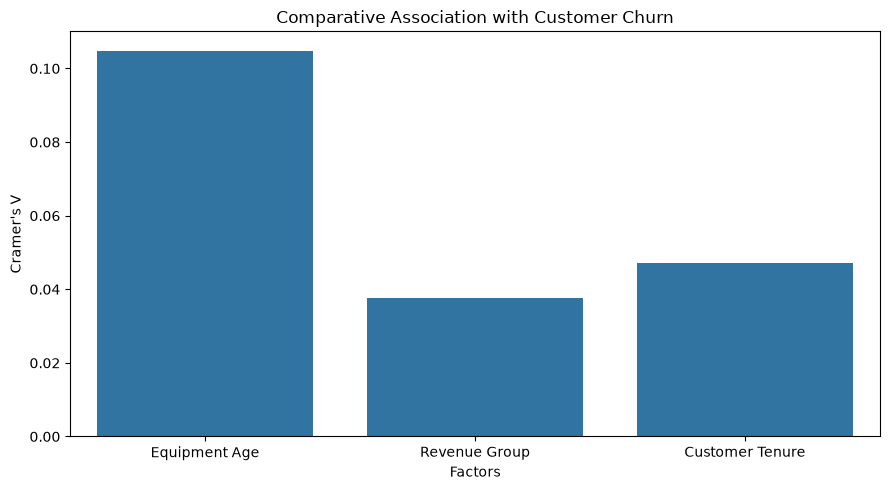

In [119]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison,
    x="Factor",
    y="Cramers_V"
)

plt.title("Comparative Association with Customer Churn")
plt.xlabel("Factors")
plt.ylabel("Cramer's V")

plt.tight_layout()
plt.show()



# Key Findings

The analysis of customer churn reveals several important insights:

1. **Equipment Age:** Customers using older equipment show higher churn rates. Customers with equipment older than two years have the highest churn rate (57.89%).

2. **Revenue Group:** Low-revenue customers have the highest churn rate (52.65%).

3. **Customer Tenure:** Customers with 13–24 months of tenure have the highest churn rate (51.78%).

4. **Statistical Association:** Equipment Age, Revenue Group, and Customer Tenure all show statistically significant associations with customer churn.

5. **Comparative Analysis:** Equipment Age has the strongest association with churn among the three examined factors.



# Conclusion

This project analyzed customer churn patterns using exploratory data analysis, data visualization, and statistical techniques.

The findings indicate that customer churn is associated with several factors, including equipment age, revenue group, and customer tenure.

Among these factors, equipment age demonstrates the strongest association with churn.

These findings can help businesses identify customer segments that may require additional attention and develop targeted customer retention strategies.

However, statistical association does not necessarily imply causation. Further predictive modeling would be required to identify the underlying causes of customer churn.


# Business Recommendations

1. **Equipment Upgrade:** Encourage customers using older equipment to upgrade their devices.

2. **Affordable Packages:** Introduce suitable packages for low-revenue customers.

3. **Customer Retention:** Develop targeted retention campaigns for customers with 13–24 months of tenure.

4. **Customer Monitoring:** Regularly monitor customer usage patterns and service interactions.

5. **Data-Driven Decisions:** Use customer data and predictive analytics to identify potential churn risks.

In [120]:
# Create output directories

import os

os.makedirs("../outputs/figures", exist_ok=True)
os.makedirs("../outputs/results", exist_ok=True)

print("Output directories are ready!")

Output directories are ready!


In [121]:
# Save Important Visualizations

# 1. Customer Churn Distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="churn")
plt.title("Customer Churn Distribution")
plt.savefig("../outputs/figures/churn_distribution.png",
            dpi=300, bbox_inches="tight")
plt.close()


# 2. Equipment Age vs Churn
equipment_analysis["churn_rate"].plot(
    kind="bar", figsize=(8, 5)
)
plt.title("Customer Churn by Equipment Age")
plt.ylabel("Churn Rate (%)")
plt.savefig("../outputs/figures/equipment_churn.png",
            dpi=300, bbox_inches="tight")
plt.close()


# 3. Revenue vs Churn
revenue_analysis["churn_rate"].plot(
    kind="bar", figsize=(8, 5)
)
plt.title("Customer Churn by Revenue")
plt.ylabel("Churn Rate (%)")
plt.savefig("../outputs/figures/revenue_churn.png",
            dpi=300, bbox_inches="tight")
plt.close()


# 4. Tenure vs Churn
tenure_analysis["churn_rate"].plot(
    kind="bar", figsize=(8, 5)
)
plt.title("Customer Churn by Tenure")
plt.ylabel("Churn Rate (%)")
plt.savefig("../outputs/figures/tenure_churn.png",
            dpi=300, bbox_inches="tight")
plt.close()


# 5. Comparative Analysis
plt.figure(figsize=(9, 5))
sns.barplot(
    data=comparison,
    x="Factor",
    y="Cramers_V"
)
plt.title("Comparative Association with Customer Churn")
plt.savefig("../outputs/figures/comparative_analysis.png",
            dpi=300, bbox_inches="tight")
plt.close()

print("All important graphs saved successfully!")

All important graphs saved successfully!


In [122]:

# Save Important Analysis Results

# 1. Comparative Analysis
comparison.to_csv(
    "../outputs/results/comparative_analysis.csv",
    index=False
)

# 2. Equipment Age Analysis
equipment_analysis.to_csv(
    "../outputs/results/equipment_analysis.csv"
)

# 3. Revenue Analysis
revenue_analysis.to_csv(
    "../outputs/results/revenue_analysis.csv"
)

# 4. Customer Tenure Analysis
tenure_analysis.to_csv(
    "../outputs/results/tenure_analysis.csv"
)

# 5. Missing Values Summary
missing_summary.to_csv(
    "../outputs/results/missing_values_summary.csv"
)

print("All analysis results saved successfully!")


All analysis results saved successfully!


In [123]:
# Verify Saved Files

for folder in ["../outputs/figures", "../outputs/results"]:
    print(f"\nFiles in {folder}:")
    for file in sorted(os.listdir(folder)):
        print("-", file)


Files in ../outputs/figures:
- churn_distribution.png
- comparative_analysis.png
- equipment_churn.png
- revenue_churn.png
- tenure_churn.png

Files in ../outputs/results:
- comparative_analysis.csv
- equipment_analysis.csv
- missing_values_summary.csv
- revenue_analysis.csv
- tenure_analysis.csv
